
# Credit Pre-Screening Engine — Loan Intake Optimisation

**Calibo AI Academy | Path 2 | KLU Batch | MUC02**  
**Prepared by:** Batch 3  
**Module:** Supervised Learning Part 1 — Regression & Problem Framing

---

## CBIM Problem Canvas

| Canvas Element | Description |
|---|---|
| **Situation (S)** | A mid-sized bank processes approximately 3,000 personal-loan applications per month. Each application requires around 25 minutes of manual review. |
| **Complication (C)** | Reviewing every application manually consumes analyst capacity, potentially increasing processing delays and reducing the time available for applications that require detailed judgement. |
| **Question (Q)** | Can a logistic regression model identify a limited group of applications for potential auto-decline, using a probability threshold that keeps historically approved applications within the bank's 5% wrong-decline tolerance? |
| **Single Source of Truth (SSOT)** | `MUC02_Credit_PreScreening_Dataset.csv` is the primary dataset for this study. The `decision` column represents historical analyst decisions; it does not indicate actual loan repayment performance. |
| **Success Criteria** | Select the threshold using validation data, evaluate it on an independent test set, measure the historical wrong-decline rate, estimate potential monthly review-time savings, and examine outcomes across demographic and employment groups. |
| **Primary Stakeholder** | Credit Policy Analyst. Other stakeholders include the Head of Retail Lending, credit analysts, and loan applicants. |

---

## Project Objective

The objective is to develop and evaluate a supervised machine learning model that predicts historical credit decisions and assesses whether a carefully restricted group of applications could be routed away from manual review.

The analysis follows Steps 5.1–5.7 of the student brief:

1. **Data Quality and Preparation** — inspect the dataset, validate the schema, document missing values, and prepare the data.
2. **Exploratory Analysis** — examine approval patterns across credit-score bands and employment categories.
3. **Feature Engineering** — derive affordability and credit-history indicators, including FOIR, loan-to-income ratio, and the New-to-Credit (NTC) flag.
4. **Model Development and Evaluation** — train logistic regression and assess classification performance using appropriate metrics.
5. **Threshold and Business Impact Analysis** — select a threshold on validation data, evaluate the risk constraint on test data, and estimate potential operational savings.
6. **Fairness Assessment** — compare relevant outcomes across gender and employment groups.
7. **Credit Policy Recommendation** — present findings, limitations, and recommendations for human-supervised use.

---

## Decision Guardrails

- **Target definition:** `Declined = 1`, `Approved = 0`.
- **Risk tolerance:** No more than 5% of applications selected for auto-decline should have been historically approved, based on the specified evaluation criterion.
- **NTC safeguard:** New-to-Credit applicants remain in the manual-review process.
- **Validation discipline:** Select the threshold using validation data and use the test set for final evaluation.
- **Feature restrictions:** Exclude `gender`, `application_id`, `application_date`, `city`, and `decision` from the model's input features.
- **Human oversight:** Treat any proposed routing policy as a recommendation requiring further review, not as an automatically approved lending policy.

> **Important limitation:** This model learns patterns in historical analyst decisions, not future repayment outcomes. A threshold meeting the 5% constraint on a finite test sample does not guarantee that future wrong-decline rates will remain below 5%. The results are a training prototype and must not be treated as authorization to automate real lending decisions.


## 01 · Load the toolkit  

Only the libraries used in the original assignment are needed: pandas, NumPy, Matplotlib, Seaborn, and scikit-learn. The random seed is fixed for repeatability.

In [21]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score, roc_auc_score,
    confusion_matrix, ConfusionMatrixDisplay, RocCurveDisplay,
    classification_report
)

SEED = 42
sns.set_theme(style="whitegrid", context="notebook", palette="deep")
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda x: f"{x:,.3f}")

expected_file = Path("MUC02_Credit_PreScreening_Dataset.csv")
if expected_file.exists():
    DATA_PATH = expected_file
else:
    csv_candidates = [
        p for p in Path(".").glob("*.csv")
        if "Credit_PreScreening" in p.name
    ]
    if not csv_candidates:
        raise FileNotFoundError(
            "Dataset not found. Put MUC02_Credit_PreScreening_Dataset.csv "
            "in the same folder as this notebook."
        )
    DATA_PATH = csv_candidates[0]

print(f"Data file: {DATA_PATH.resolve()}")
print(f"Reproducibility seed: {SEED}")

Data file: C:\usecase-2\MUC02_Credit_PreScreening_Dataset 1.csv
Reproducibility seed: 42


## 02 · Establish data quality

Load the source file and inspect its schema, missingness, duplicates, target distribution, and value ranges before changing any records. The raw profile is captured first; the cleaned profile is generated after the documented cleaning steps.


In [22]:
import pandas as pd

# 1. Load the original dataset
# Try common project/notebook locations first, then the original Windows path.
candidate_paths = [
    Path("MUC02_Credit_PreScreening_Dataset.csv"),
    Path("MUC02_Credit_PreScreening_Dataset 1.csv"),
    Path("data") / "MUC02_Credit_PreScreening_Dataset.csv",
    Path(r"C:\\usecase-2\\MUC02_Credit_PreScreening_Dataset 1.csv"),
]
dataset_path = next((candidate for candidate in candidate_paths if candidate.exists()), None)

if dataset_path is None:
    raise FileNotFoundError(
        "Dataset not found. Place 'MUC02_Credit_PreScreening_Dataset.csv' "
        "or 'MUC02_Credit_PreScreening_Dataset 1.csv' beside this notebook, "
        "or update candidate_paths to the dataset's location."
    )

df = pd.read_csv(dataset_path)
print(f"Loaded dataset from: {dataset_path.resolve()}")


# 2. Define required columns
required = [
    "application_id", "application_date", "age", "gender", "city",
    "city_tier", "employment_type", "years_in_current_job",
    "monthly_income", "existing_emi", "credit_score",
    "credit_history_months", "num_active_loans",
    "delinquencies_24m", "loan_purpose", "loan_amount",
    "tenure_months", "proposed_emi", "decision"
]

# 3. Validate the schema
missing_columns = sorted(set(required) - set(df.columns))

if missing_columns:
    raise ValueError(f"Required columns missing: {missing_columns}")

# 4. Generate the raw data-quality profile
profile_before = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_n": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "distinct_n": df.nunique(dropna=False)
})

# 5. Display raw data
print("BEFORE CLEANING — RAW DATA")
print("=" * 45)

display(df.head(5))
display(profile_before)

print(f"Dataset size: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate application IDs:", int(df["application_id"].duplicated().sum()))

print("\nDecision distribution before cleaning:")
display(
    df["decision"]
    .value_counts(dropna=False)
    .rename("applications")
    .to_frame()
)

Loaded dataset from: C:\usecase-2\MUC02_Credit_PreScreening_Dataset 1.csv
BEFORE CLEANING — RAW DATA


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.100,"95,000.000","23,500.000",784.000,109,2,0,Home Renovation,"240,000.000",48,"6,600.000",Approved
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.600,"43,000.000","8,500.000",790.000,162,2,0,Wedding,"145,000.000",36,"5,000.000",Approved
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.400,"35,000.000","3,500.000",718.000,151,1,1,Medical,"345,000.000",36,"11,800.000",Approved
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.800,"44,500.000",0.000,NaN,0,0,0,Travel,"135,000.000",36,"4,600.000",Approved
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.100,"83,500.000","6,000.000",700.000,127,1,3,Medical,"700,000.000",24,"33,600.000",Declined


,dtype,missing_n,missing_pct,distinct_n
application_id,str,0,0.000,12000
application_date,str,0,0.000,183
age,int64,0,0.000,39
gender,str,0,0.000,2
city,str,0,0.000,26
city_tier,int64,0,0.000,3
employment_type,str,0,0.000,4
years_in_current_job,float64,0,0.000,217
monthly_income,float64,441,3.680,443
existing_emi,float64,0,0.000,137


Dataset size: 12,000 rows × 19 columns
Exact duplicate rows: 0
Duplicate application IDs: 0

Decision distribution before cleaning:


,applications
decision,
Approved,6353
Declined,5647


In [23]:
# The raw profile is shown in Cell 4. The cleaned profile is generated
# after the documented cleaning operations in the next section.
print("Raw profile captured. Run the cleaning section before creating profile_after.")


Raw profile captured. Run the cleaning section before creating profile_after.


## 03 · Clean with a documented reason

The cleaning rules below preserve NTC applications, correct the documented salaried-income unit anomaly, and impute missing income using employment-group medians. Record the assumptions and verify the resulting ranges before modelling.


In [24]:
for col in ["decision", "employment_type", "loan_purpose", "gender"]:
    df[col] = df[col].astype("string").str.strip()

df["application_date"] = pd.to_datetime(df["application_date"], errors="coerce")

# Correct the documented annual-income-entered-as-monthly anomaly.
high_income = df["monthly_income"].gt(600_000) & df["employment_type"].eq("Salaried")
high_income_n = int(high_income.sum())
df.loc[high_income, "monthly_income"] = df.loc[high_income, "monthly_income"] / 12

# Missing income: employment-type median.
income_missing_n = int(df["monthly_income"].isna().sum())
job_medians = df.groupby("employment_type")["monthly_income"].median()
df["monthly_income"] = df["monthly_income"].fillna(df["employment_type"].map(job_medians))

# A blank credit score is a meaningful NTC signal in this dataset; do not drop these rows.
df["is_ntc"] = df["credit_score"].isna().astype(int)
ntc_n = int(df["is_ntc"].sum())
ntc_nonzero_history = int(
    (df.loc[df["is_ntc"].eq(1), "credit_history_months"].fillna(-1) != 0).sum()
)

if df["decision"].isna().any():
    raise ValueError("The target 'decision' contains missing values.")
valid_labels = {"Approved", "Declined"}
unexpected = set(df["decision"].dropna().unique()) - valid_labels
if unexpected:
    raise ValueError(f"Unexpected decision values: {unexpected}")
if df["monthly_income"].isna().any():
    raise ValueError("Income is still missing after employment-median imputation.")
if (df["monthly_income"] <= 0).any():
    raise ValueError("Non-positive income found; investigate before calculating FOIR.")

print(f"High salaried incomes divided by 12: {high_income_n}")
print(f"Missing incomes imputed: {income_missing_n}")
print(f"Rows with no credit score retained: {ntc_n}")
print(f"NTC rows whose credit_history_months is not zero: {ntc_nonzero_history}")
print(f"Approval rate: {df['decision'].eq('Approved').mean() * 100:.1f}%")

High salaried incomes divided by 12: 12
Missing incomes imputed: 441
Rows with no credit score retained: 1039
NTC rows whose credit_history_months is not zero: 0
Approval rate: 52.9%


In [25]:
# Post-cleaning data-quality profile (run after Cell 7)
profile_after = pd.DataFrame({
    "dtype": df.dtypes.astype(str),
    "missing_n": df.isna().sum(),
    "missing_pct": (df.isna().mean() * 100).round(2),
    "distinct_n": df.nunique(dropna=False)
})

print("AFTER CLEANING — CLEANED DATA")
print("=" * 45)
display(df.head(5))
display(profile_after)

print(f"Dataset size: {df.shape[0]:,} rows × {df.shape[1]} columns")
print("Exact duplicate rows:", int(df.duplicated().sum()))
print("Duplicate application IDs:", int(df["application_id"].duplicated().sum()))
print("\\nDecision distribution after cleaning:")
display(df["decision"].value_counts(dropna=False).rename("applications").to_frame())


AFTER CLEANING — CLEANED DATA


,application_id,application_date,age,gender,city,city_tier,employment_type,years_in_current_job,monthly_income,existing_emi,credit_score,credit_history_months,num_active_loans,delinquencies_24m,loan_purpose,loan_amount,tenure_months,proposed_emi,decision,is_ntc
0,APP100001,2026-04-01,28,Male,Hyderabad,1,Salaried,4.100,"95,000.000","23,500.000",784.000,109,2,0,Home Renovation,"240,000.000",48,"6,600.000",Approved,0
1,APP100002,2026-04-01,36,Female,Raipur,3,Business Owner,0.600,"43,000.000","8,500.000",790.000,162,2,0,Wedding,"145,000.000",36,"5,000.000",Approved,0
2,APP100003,2026-04-01,35,Male,Nagpur,2,Salaried,4.400,"35,000.000","3,500.000",718.000,151,1,1,Medical,"345,000.000",36,"11,800.000",Approved,0
3,APP100004,2026-04-01,42,Male,Jaipur,2,Salaried,5.800,"44,500.000",0.000,NaN,0,0,0,Travel,"135,000.000",36,"4,600.000",Approved,1
4,APP100005,2026-04-01,34,Male,Kochi,2,Self-Employed Professional,2.100,"83,500.000","6,000.000",700.000,127,1,3,Medical,"700,000.000",24,"33,600.000",Declined,0


,dtype,missing_n,missing_pct,distinct_n
application_id,str,0,0.000,12000
application_date,datetime64[us],0,0.000,183
age,int64,0,0.000,39
gender,string,0,0.000,2
city,str,0,0.000,26
city_tier,int64,0,0.000,3
employment_type,string,0,0.000,4
years_in_current_job,float64,0,0.000,217
monthly_income,float64,0,0.000,430
existing_emi,float64,0,0.000,137


Dataset size: 12,000 rows × 20 columns
Exact duplicate rows: 0
Duplicate application IDs: 0
\nDecision distribution after cleaning:


,applications
decision,
Approved,6353
Declined,5647


**Cleaning decisions to report:** employment-specific median for missing income; divide the documented high salaried values by 12; retain blank-score applicants and mark them as NTC. Do not remove duplicates automatically without checking whether the records are genuinely invalid.

## 04 · Find the policy signals  

Compare historical approval rates by the required credit-score bands and employment type. These are descriptions of the bank's past decisions, not proof of repayment performance.

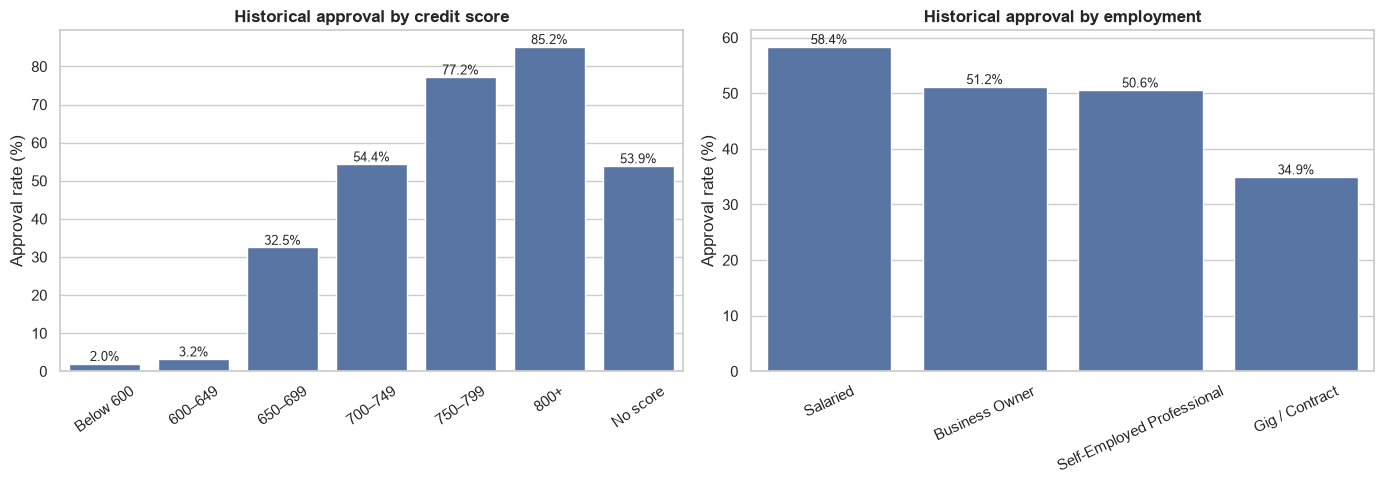

,approval_rate_pct
credit_score_band,
Below 600,2.000
600–649,3.200
650–699,32.500
700–749,54.400
750–799,77.200
800+,85.200
No score,53.900


,approval_rate_pct
employment_type,
Salaried,58.400
Business Owner,51.200
Self-Employed Professional,50.600
Gig / Contract,34.900


In [26]:
score_edges = [-np.inf, 599, 649, 699, 749, 799, np.inf]
score_names = ["Below 600", "600–649", "650–699", "700–749", "750–799", "800+"]
df["credit_score_band"] = pd.cut(df["credit_score"], bins=score_edges, labels=score_names).astype("object")
df.loc[df["credit_score"].isna(), "credit_score_band"] = "No score"
score_order = score_names + ["No score"]

score_rate = (
    df.groupby("credit_score_band", observed=False)["decision"]
      .apply(lambda s: s.eq("Approved").mean() * 100)
      .reindex(score_order)
)
job_rate = (
    df.groupby("employment_type")["decision"]
      .apply(lambda s: s.eq("Approved").mean() * 100)
      .sort_values(ascending=False)
)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))
sns.barplot(x=score_rate.index, y=score_rate.values, ax=axes[0])
axes[0].set_title("Historical approval by credit score", weight="bold")
axes[0].set_xlabel("")
axes[0].set_ylabel("Approval rate (%)")
axes[0].tick_params(axis="x", rotation=35)
for patch in axes[0].patches:
    axes[0].annotate(f"{patch.get_height():.1f}%",
                     (patch.get_x()+patch.get_width()/2, patch.get_height()),
                     ha="center", va="bottom", fontsize=9)

sns.barplot(x=job_rate.index, y=job_rate.values, ax=axes[1])
axes[1].set_title("Historical approval by employment", weight="bold")
axes[1].set_xlabel("")
axes[1].set_ylabel("Approval rate (%)")
axes[1].tick_params(axis="x", rotation=25)
for patch in axes[1].patches:
    axes[1].annotate(f"{patch.get_height():.1f}%",
                     (patch.get_x()+patch.get_width()/2, patch.get_height()),
                     ha="center", va="bottom", fontsize=9)
plt.tight_layout()
plt.show()

display(score_rate.rename("approval_rate_pct").to_frame().round(1))
display(job_rate.rename("approval_rate_pct").to_frame().round(1))

Approvals increase sharply in the 650–699 credit score band (32.5%) and continue rising to 85.2% for applicants scoring 800 or above. Applicants with no credit score have a 53.9% approval rate, which is higher than the 650–699 and lower score bands but below most higher-scoring groups. Gig / Contract workers have the lowest approval rate at 34.9%, compared with 58.4% for salaried applicants.

## 05 · Build the affordability view  

FOIR is the proportion of monthly income committed to existing and proposed EMIs. Loan-to-income compares the requested amount with annual income.

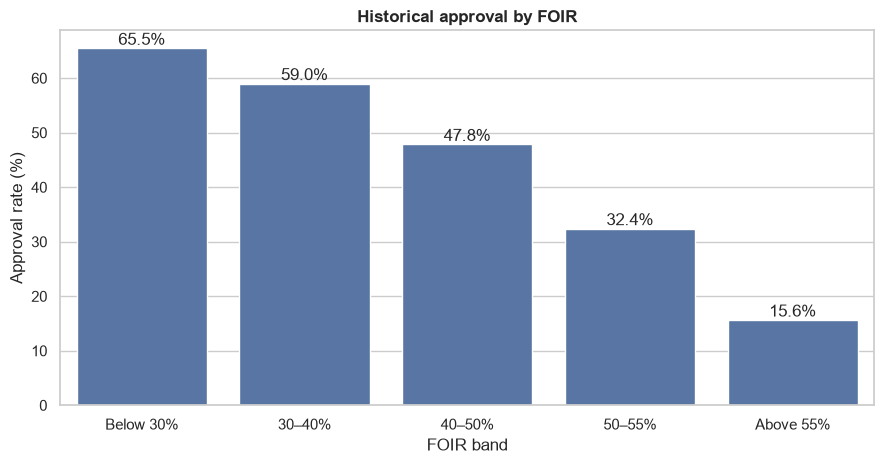

,approval_rate_pct
foir_band,
Below 30%,65.500
30–40%,59.000
40–50%,47.800
50–55%,32.400
Above 55%,15.600


In [27]:
df["foir"] = (df["existing_emi"] + df["proposed_emi"]) / df["monthly_income"]
df["loan_to_income"] = df["loan_amount"] / (df["monthly_income"] * 12)

foir_edges = [-np.inf, 0.30, 0.40, 0.50, 0.55, np.inf]
foir_names = ["Below 30%", "30–40%", "40–50%", "50–55%", "Above 55%"]
df["foir_band"] = pd.cut(df["foir"], bins=foir_edges, labels=foir_names, right=False)
foir_rate = (
    df.groupby("foir_band", observed=False)["decision"]
      .apply(lambda s: s.eq("Approved").mean() * 100)
      .reindex(foir_names)
)

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.barplot(x=foir_rate.index, y=foir_rate.values, ax=ax)
ax.set_title("Historical approval by FOIR", weight="bold")
ax.set_xlabel("FOIR band")
ax.set_ylabel("Approval rate (%)")
for patch in ax.patches:
    ax.annotate(f"{patch.get_height():.1f}%",
                (patch.get_x()+patch.get_width()/2, patch.get_height()),
                ha="center", va="bottom")
plt.tight_layout()
plt.show()
display(foir_rate.rename("approval_rate_pct").to_frame().round(1))

**Policy prompt:** Where does approval fall most sharply? Suggest a tentative FOIR limit based on the chart, while noting that historical approval patterns alone do not establish whether a loan will be repaid.

## 06 · Set up a leakage-aware modelling workflow  

Predict `Declined = 1` and `Approved = 0`. Exclude IDs, date, city, gender, and the decision itself. A three-way split separates model fitting, threshold selection, and final evaluation.

In [28]:
features = [
    "credit_score", "is_ntc", "foir", "loan_to_income", "delinquencies_24m",
    "num_active_loans", "years_in_current_job", "age", "tenure_months",
    "city_tier", "employment_type", "loan_purpose"
]
forbidden = {"application_id", "application_date", "city", "gender", "decision"}
if forbidden.intersection(features):
    raise ValueError(f"Prohibited features found: {forbidden.intersection(features)}")

X = df[features].copy()
y = df["decision"].map({"Approved": 0, "Declined": 1}).astype(int)

X_train, X_hold, y_train, y_hold = train_test_split(
    X, y, test_size=0.40, random_state=SEED, stratify=y
)
X_valid, X_test, y_valid, y_test = train_test_split(
    X_hold, y_hold, test_size=0.50, random_state=SEED, stratify=y_hold
)

numeric_cols = [
    "credit_score", "is_ntc", "foir", "loan_to_income", "delinquencies_24m",
    "num_active_loans", "years_in_current_job", "age", "tenure_months", "city_tier"
]
categorical_cols = ["employment_type", "loan_purpose"]

numeric_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scale", StandardScaler())
])
categorical_pipe = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encode", OneHotEncoder(handle_unknown="ignore"))
])
prep = ColumnTransformer([
    ("numeric", numeric_pipe, numeric_cols),
    ("categorical", categorical_pipe, categorical_cols)
])
model = Pipeline([
    ("preprocessing", prep),
    ("logistic_regression", LogisticRegression(max_iter=2000, random_state=SEED))
])

print(f"Train: {len(X_train):,} | Validation: {len(X_valid):,} | Test: {len(X_test):,}")

Train: 7,200 | Validation: 2,400 | Test: 2,400


## 07 · Fit and assess the model  

The pipeline learns imputation, scaling, and encoding from the training data only. The 0.50 cutoff is shown as a baseline; it is not automatically the business policy.

,metric_value
Accuracy,0.780
Precision · Declined,0.782
Recall · Declined,0.737
F1 · Declined,0.759
ROC-AUC,0.867


Classification report at threshold 0.50
              precision    recall  f1-score   support

    Approved       0.78      0.82      0.80      1271
    Declined       0.78      0.74      0.76      1129

    accuracy                           0.78      2400
   macro avg       0.78      0.78      0.78      2400
weighted avg       0.78      0.78      0.78      2400



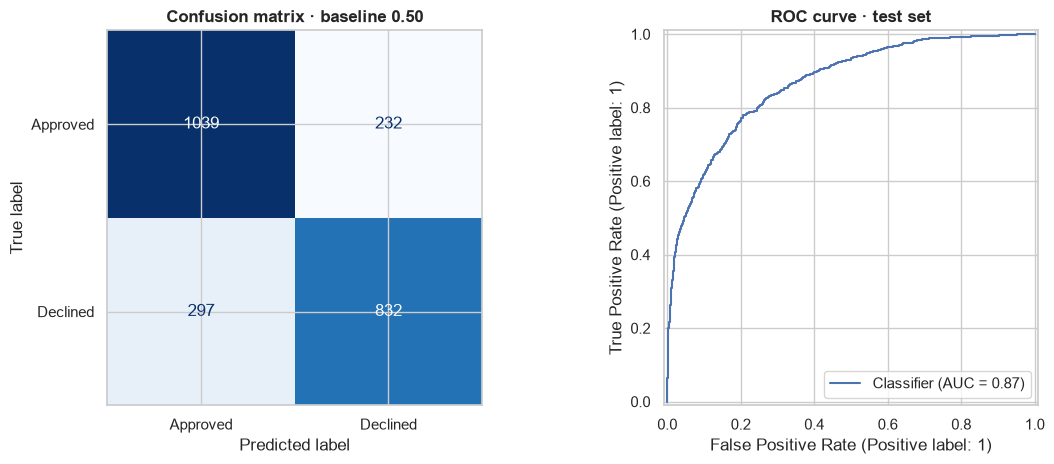

In [29]:
model.fit(X_train, y_train)
p_valid = model.predict_proba(X_valid)[:, 1]
p_test = model.predict_proba(X_test)[:, 1]

pred_050 = (p_test >= 0.50).astype(int)
scores = pd.Series({
    "Accuracy": accuracy_score(y_test, pred_050),
    "Precision · Declined": precision_score(y_test, pred_050, zero_division=0),
    "Recall · Declined": recall_score(y_test, pred_050, zero_division=0),
    "F1 · Declined": f1_score(y_test, pred_050, zero_division=0),
    "ROC-AUC": roc_auc_score(y_test, p_test)
}, name="metric_value")
display(scores.to_frame().round(4))

print("Classification report at threshold 0.50")
print(classification_report(
    y_test, pred_050, labels=[0, 1],
    target_names=["Approved", "Declined"], zero_division=0
))

fig, axes = plt.subplots(1, 2, figsize=(12, 4.8))
ConfusionMatrixDisplay.from_predictions(
    y_test, pred_050, display_labels=["Approved", "Declined"],
    cmap="Blues", colorbar=False, ax=axes[0]
)
axes[0].set_title("Confusion matrix · baseline 0.50", weight="bold")
RocCurveDisplay.from_predictions(y_test, p_test, ax=axes[1])
axes[1].set_title("ROC curve · test set", weight="bold")
plt.tight_layout()
plt.show()

**Business meaning:** a false positive is an application predicted as Declined even though the historical decision was Approved. That is the wrong-decline outcome the policy must control.

The fitted model and preprocessing pipeline are used below to retrieve the exact transformed feature names and coefficients.\n

The fitted pipeline below supplies the actual transformed feature names. This avoids guessed feature labels and keeps the coefficient plot reproducible.\n

In [30]:
# Extract coefficients and transformed feature names from the fitted pipeline
fitted_logistic = model.named_steps["logistic_regression"]
fitted_preprocessor = model.named_steps["preprocessing"]

feature_names = fitted_preprocessor.get_feature_names_out()
coefficients = fitted_logistic.coef_.ravel()

if len(feature_names) != len(coefficients):
    raise ValueError("Feature-name count does not match coefficient count.")

coef_df = pd.DataFrame({
    "feature": feature_names,
    "coefficient": coefficients
})
coef_df["magnitude"] = coef_df["coefficient"].abs()

print("Number of transformed features:", len(coef_df))
display(
    coef_df.nlargest(14, "magnitude")
           .sort_values("coefficient")
           .round(3)
)


Number of transformed features: 21


,feature,coefficient,magnitude
0,numeric__credit_score,-1.003,1.003
12,categorical__employment_type_Salaried,-0.425,0.425
3,numeric__loan_to_income,-0.213,0.213
14,categorical__loan_purpose_Consumer Durables,-0.212,0.212
13,categorical__employment_type_Self-Employed Pro...,-0.158,0.158
6,numeric__years_in_current_job,-0.125,0.125
16,categorical__loan_purpose_Education,-0.108,0.108
5,numeric__num_active_loans,0.090,0.090
8,numeric__tenure_months,0.110,0.110
15,categorical__loan_purpose_Debt Consolidation,0.350,0.350


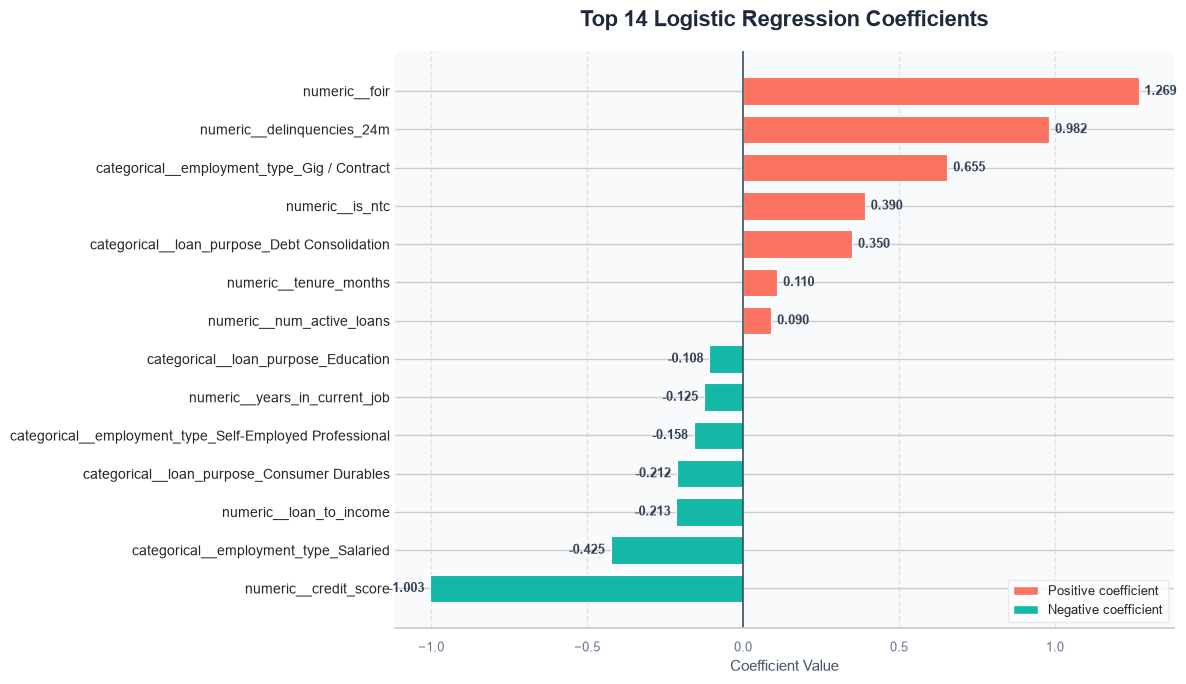

,feature,coefficient,magnitude
0,numeric__foir,1.269,1.269
1,numeric__credit_score,-1.003,1.003
2,numeric__delinquencies_24m,0.982,0.982
3,categorical__employment_type_Gig / Contract,0.655,0.655
4,categorical__employment_type_Salaried,-0.425,0.425
5,numeric__is_ntc,0.390,0.390
6,categorical__loan_purpose_Debt Consolidation,0.350,0.350
7,numeric__loan_to_income,-0.213,0.213
8,categorical__loan_purpose_Consumer Durables,-0.212,0.212
9,categorical__employment_type_Self-Employed Pro...,-0.158,0.158


In [31]:
# Select the 14 features with the largest absolute coefficients
top_coef = (
    coef_df.nlargest(14, "magnitude")
    .sort_values("coefficient")
    .copy()
)

# Assign colours: coral for positive, teal for negative
colors = [
    "#F97360" if value > 0 else "#14B8A6"
    for value in top_coef["coefficient"]
]

# Create an attractive horizontal bar chart
fig, ax = plt.subplots(figsize=(12, 7))

bars = ax.barh(
    top_coef["feature"],
    top_coef["coefficient"],
    color=colors,
    height=0.72,
    edgecolor="white",
    linewidth=0.8
)

# Zero reference line
ax.axvline(0, color="#334155", linewidth=1.4, alpha=0.8)

# Add coefficient value labels
for bar, value in zip(bars, top_coef["coefficient"]):
    offset = 0.015 * max(coef_df["magnitude"].max(), 1)
    ax.text(
        value + (offset if value >= 0 else -offset),
        bar.get_y() + bar.get_height() / 2,
        f"{value:.3f}",
        va="center",
        ha="left" if value >= 0 else "right",
        fontsize=9,
        fontweight="bold",
        color="#334155"
    )

# Styling
ax.set_title(
    "Top 14 Logistic Regression Coefficients",
    fontsize=16,
    fontweight="bold",
    color="#1E293B",
    pad=18
)

ax.set_xlabel(
    "Coefficient Value",
    fontsize=11,
    fontweight="medium",
    color="#475569"
)
ax.set_ylabel("")

ax.set_facecolor("#F8FAFC")
fig.patch.set_facecolor("white")
ax.grid(axis="x", linestyle="--", alpha=0.25, color="#94A3B8")
ax.set_axisbelow(True)

# Remove unnecessary borders
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_visible(False)

ax.tick_params(axis="y", labelsize=10, length=0)
ax.tick_params(axis="x", labelsize=9, colors="#64748B")

# Legend
from matplotlib.patches import Patch

legend_items = [
    Patch(facecolor="#F97360", label="Positive coefficient"),
    Patch(facecolor="#14B8A6", label="Negative coefficient")
]

ax.legend(
    handles=legend_items,
    loc="lower right",
    frameon=True,
    facecolor="white",
    edgecolor="#E2E8F0",
    fontsize=9
)

plt.tight_layout()
plt.show()

# Display coefficient summary
display(
    top_coef[["feature", "coefficient", "magnitude"]]
    .sort_values("magnitude", ascending=False)
    .round(3)
    .reset_index(drop=True)
)

## 09 · Apply the 5% risk gate  

New-to-credit applicants always remain with a human reviewer. On the validation set, find the lowest tested threshold where no more than 5% of auto-declines were historically approved. Then lock the threshold before checking the test set.

,threshold,auto_declined_n,auto_declined_pct,wrong_approved_n,wrong_pct_of_auto_declines,historical_declines_caught_pct
0,0.500,984,41.000,190,19.310,70.270
1,0.600,833,34.710,124,14.890,62.740
2,0.700,689,28.710,72,10.450,54.600
3,0.800,547,22.790,41,7.500,44.780
4,0.850,454,18.920,29,6.390,37.610
5,0.900,358,14.920,18,5.030,30.090
6,0.950,237,9.880,6,2.530,20.440


Validation-selected threshold: 0.95


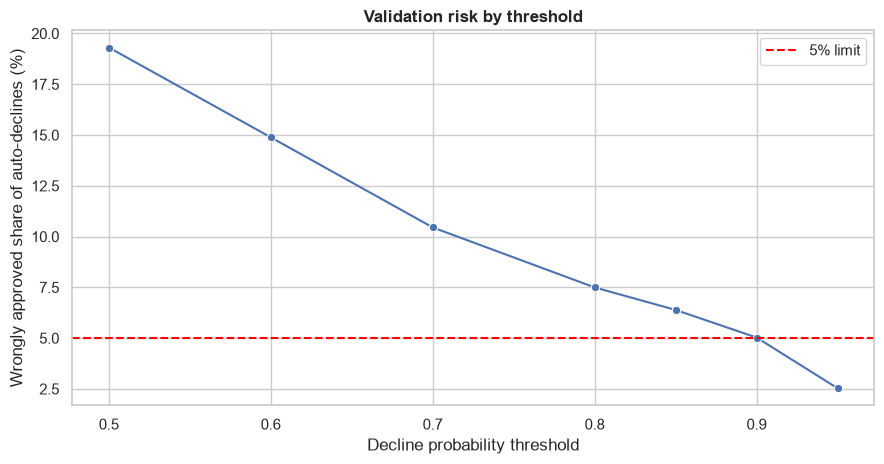

In [32]:
THRESHOLDS = [0.50, 0.60, 0.70, 0.80, 0.85, 0.90, 0.95]

def evaluate_policy(y_true, prob, ntc_flag, threshold):
    actual = np.asarray(y_true)
    prob = np.asarray(prob)
    eligible = np.asarray(ntc_flag).astype(int) == 0
    auto = (prob >= threshold) & eligible
    n_auto = int(auto.sum())
    wrong = int(((actual == 0) & auto).sum())
    declined_actual = int((actual == 1).sum())
    caught = int(((actual == 1) & auto).sum())
    return {
        "threshold": threshold,
        "auto_declined_n": n_auto,
        "auto_declined_pct": auto.mean() * 100,
        "wrong_approved_n": wrong,
        "wrong_pct_of_auto_declines": wrong / n_auto * 100 if n_auto else np.nan,
        "historical_declines_caught_pct": caught / declined_actual * 100 if declined_actual else np.nan
    }

validation_results = pd.DataFrame([
    evaluate_policy(y_valid, p_valid, X_valid["is_ntc"], t)
    for t in THRESHOLDS
])
display(validation_results.round(2))

safe_results = validation_results[
    validation_results["wrong_pct_of_auto_declines"].notna()
    & (validation_results["wrong_pct_of_auto_declines"] <= 5.0)
].sort_values("threshold")

selected_threshold = float(safe_results.iloc[0]["threshold"]) if not safe_results.empty else None
if selected_threshold is None:
    print("No tested threshold met the validation risk limit. Do not auto-decline.")
else:
    print(f"Validation-selected threshold: {selected_threshold:.2f}")

fig, ax = plt.subplots(figsize=(9, 4.8))
sns.lineplot(data=validation_results, x="threshold",
             y="wrong_pct_of_auto_declines", marker="o", ax=ax)
ax.axhline(5, color="red", linestyle="--", label="5% limit")
ax.set_title("Validation risk by threshold", weight="bold")
ax.set_xlabel("Decline probability threshold")
ax.set_ylabel("Wrongly approved share of auto-declines (%)")
ax.legend()
plt.tight_layout()
plt.show()

## 10 · Confirm the policy on held-out test data  

The test set was not used to choose the threshold. Convert the test result into the bank's units: applications and analyst hours per month.

In [33]:
if selected_threshold is None:
    final_policy = None
    print("No automatic-decline policy recommended.")
else:
    final_policy = evaluate_policy(
        y_test, p_test, X_test["is_ntc"], selected_threshold
    )
    display(pd.DataFrame([final_policy]).round(2))

    MONTHLY_APPLICATIONS = 3000
    REVIEW_MINUTES = 25
    est_monthly_auto = MONTHLY_APPLICATIONS * final_policy["auto_declined_pct"] / 100
    est_monthly_hours = est_monthly_auto * REVIEW_MINUTES / 60

    print(f"Estimated applications routed away from review/month: {est_monthly_auto:,.0f}")
    print(f"Estimated analyst hours freed/month: {est_monthly_hours:,.1f}")
    print(f"Test wrong-decline share: {final_policy['wrong_pct_of_auto_declines']:.2f}%")

,threshold,auto_declined_n,auto_declined_pct,wrong_approved_n,wrong_pct_of_auto_declines,historical_declines_caught_pct
0,0.950,231,9.620,3,1.300,20.190


Estimated applications routed away from review/month: 289
Estimated analyst hours freed/month: 120.3
Test wrong-decline share: 1.30%


## 11 · Check outcomes by gender  

Gender is not a model feature, but other features may act as proxies. Compare historical approval and policy auto-decline rates, and review differences within employment groups.

The fairness audit below is evaluated on the held-out test set and retains the NTC human-review rule.\n

In [34]:
# ============================================================
# FAIRNESS AUDIT ON THE HELD-OUT TEST SET ONLY
# Gender is NOT a model feature.
# It is used only for post-model fairness monitoring.
# ============================================================

# Step 1: Check whether a valid threshold was selected
if selected_threshold is None:
    raise RuntimeError(
        "No threshold passed the validation 5% risk gate. "
        "Keep all applications in manual review."
    )


# Step 2: Align demographic and contextual data with X_test and y_test
# Preserved indices ensure that all rows correspond to the same applications.

fairness_test = df.loc[
    X_test.index,
    [
        "gender",
        "employment_type",
        "monthly_income",
        "decision"
    ]
].copy()

fairness_test["actual_approved"] = y_test.eq(0).to_numpy()
fairness_test["decline_probability"] = p_test
fairness_test["is_ntc"] = X_test["is_ntc"].to_numpy().astype(int)


# Step 3: Apply the policy rule
# Only scored applicants can enter the automatic-decline lane.

fairness_test["auto_declined"] = (
    (fairness_test["decline_probability"] >= selected_threshold)
    & (fairness_test["is_ntc"] == 0)
)


# Step 4: Calculate overall test-set results by gender

gender_results = (
    fairness_test
    .groupby("gender", dropna=False)
    .agg(
        test_applications=("decision", "size"),
        historical_approval_pct=(
            "actual_approved",
            lambda s: s.mean() * 100
        ),
        model_auto_decline_pct=(
            "auto_declined",
            lambda s: s.mean() * 100
        ),
        median_monthly_income=("monthly_income", "median")
    )
)


# Step 5: Calculate employment-type distribution by gender
# This includes the percentage of Gig / Contract applicants.

gender_mix = (
    fairness_test
    .assign(
        is_gig_contract=fairness_test["employment_type"].eq(
            "Gig / Contract"
        )
    )
    .groupby("gender", dropna=False)
    .agg(
        gig_contract_share_pct=(
            "is_gig_contract",
            lambda s: s.mean() * 100
        )
    )
)

# Combine the overall gender results and employment mix
gender_results = gender_results.join(gender_mix)


# Step 6: Display overall gender comparison

print(f"Fairness audit threshold: {selected_threshold:.2f}")

print("\nTest-set gender comparison:")
display(gender_results.round(2))


# Step 7: Compare gender results within each employment type
# This helps identify whether overall differences persist
# after considering employment category.

gender_employment_results = (
    fairness_test
    .groupby(
        ["employment_type", "gender"],
        dropna=False
    )
    .agg(
        test_applications=("decision", "size"),
        historical_approval_pct=(
            "actual_approved",
            lambda s: s.mean() * 100
        ),
        model_auto_decline_pct=(
            "auto_declined",
            lambda s: s.mean() * 100
        ),
        median_monthly_income=("monthly_income", "median")
    )
    .reset_index()
)


# Step 8: Display gender comparison within employment type

print("\nGender comparison within employment type:")
display(gender_employment_results.round(2))


# Step 9: Identify small groups
# Percentages from very small groups may be unstable.
# Groups with fewer than 30 applications are flagged.

MIN_GROUP_N = 30

small_groups = gender_employment_results[
    gender_employment_results["test_applications"] < MIN_GROUP_N
]


# Step 10: Display small-group warnings

if not small_groups.empty:
    print(
        f"\nCAUTION: Some employment × gender groups "
        f"have fewer than {MIN_GROUP_N} test cases."
    )

    display(
        small_groups[
            [
                "employment_type",
                "gender",
                "test_applications"
            ]
        ]
    )
else:
    print(
        f"\nAll employment × gender groups have at least "
        f"{MIN_GROUP_N} test cases."
    )

Fairness audit threshold: 0.95

Test-set gender comparison:


,test_applications,historical_approval_pct,model_auto_decline_pct,median_monthly_income,gig_contract_share_pct
gender,,,,,
Female,714,51.120,10.640,"46,000.000",20.450
Male,1686,53.740,9.190,"56,500.000",11.510



Gender comparison within employment type:


,employment_type,gender,test_applications,historical_approval_pct,model_auto_decline_pct,median_monthly_income
0,Business Owner,Female,60,48.330,10.000,"63,750.000"
1,Business Owner,Male,297,51.520,10.770,"69,500.000"
2,Gig / Contract,Female,146,35.620,23.290,"25,250.000"
3,Gig / Contract,Male,194,34.020,21.130,"28,250.000"
4,Salaried,Female,409,56.970,5.870,"46,500.000"
5,Salaried,Male,998,58.720,6.810,"52,500.000"
6,Self-Employed Professional,Female,99,51.520,12.120,"75,000.000"
7,Self-Employed Professional,Male,197,51.270,7.110,"78,500.000"



All employment × gender groups have at least 30 test cases.


In [35]:
# Fairness audit on the held-out test set only.
# Gender is not a model feature; it is used only for post-model monitoring.

if selected_threshold is None:
    raise RuntimeError("No threshold passed the validation 5% risk gate. Keep all applications in manual review.")

# Align demographic/context rows exactly with X_test and y_test using preserved indices.
fairness_test = df.loc[X_test.index, [
    "gender", "employment_type", "monthly_income", "decision"
]].copy()

fairness_test["actual_approved"] = y_test.eq(0).to_numpy()
fairness_test["decline_probability"] = p_test
fairness_test["is_ntc"] = X_test["is_ntc"].to_numpy().astype(int)

# Policy rule: only scored applicants can enter the auto-decline lane.
fairness_test["auto_declined"] = (
    (fairness_test["decline_probability"] >= selected_threshold)
    & (fairness_test["is_ntc"] == 0)
)

# Overall test-set results by gender.
gender_results = (
    fairness_test.groupby("gender", dropna=False)
    .agg(
        test_applications=("decision", "size"),
        historical_approval_pct=("actual_approved", lambda s: s.mean() * 100),
        model_auto_decline_pct=("auto_declined", lambda s: s.mean() * 100),
        median_monthly_income=("monthly_income", "median")
    )
)

# Employment-type mix by gender, including Gig/Contract share.
gender_mix = (
    fairness_test.assign(
        is_gig_contract=fairness_test["employment_type"].eq("Gig / Contract")
    )
    .groupby("gender", dropna=False)
    .agg(gig_contract_share_pct=("is_gig_contract", lambda s: s.mean() * 100))
)
gender_results = gender_results.join(gender_mix)

print(f"Fairness audit threshold: {selected_threshold:.2f}")
print("Test-set gender comparison:")
display(gender_results.round(2))

# Within-employment comparison to check whether overall differences persist.
gender_employment_results = (
    fairness_test.groupby(["employment_type", "gender"], dropna=False)
    .agg(
        test_applications=("decision", "size"),
        historical_approval_pct=("actual_approved", lambda s: s.mean() * 100),
        model_auto_decline_pct=("auto_declined", lambda s: s.mean() * 100),
        median_monthly_income=("monthly_income", "median")
    )
    .reset_index()
)

print("Gender comparison within employment type:")
display(gender_employment_results.round(2))

# Small groups can produce unstable percentages; flag them for cautious interpretation.
MIN_GROUP_N = 30
small_groups = gender_employment_results[
    gender_employment_results["test_applications"] < MIN_GROUP_N
]
if not small_groups.empty:
    print(f"CAUTION: Some employment × gender groups have fewer than {MIN_GROUP_N} test cases.")
    display(small_groups[["employment_type", "gender", "test_applications"]])


Fairness audit threshold: 0.95
Test-set gender comparison:


,test_applications,historical_approval_pct,model_auto_decline_pct,median_monthly_income,gig_contract_share_pct
gender,,,,,
Female,714,51.120,10.640,"46,000.000",20.450
Male,1686,53.740,9.190,"56,500.000",11.510


Gender comparison within employment type:


,employment_type,gender,test_applications,historical_approval_pct,model_auto_decline_pct,median_monthly_income
0,Business Owner,Female,60,48.330,10.000,"63,750.000"
1,Business Owner,Male,297,51.520,10.770,"69,500.000"
2,Gig / Contract,Female,146,35.620,23.290,"25,250.000"
3,Gig / Contract,Male,194,34.020,21.130,"28,250.000"
4,Salaried,Female,409,56.970,5.870,"46,500.000"
5,Salaried,Male,998,58.720,6.810,"52,500.000"
6,Self-Employed Professional,Female,99,51.520,12.120,"75,000.000"
7,Self-Employed Professional,Male,197,51.270,7.110,"78,500.000"


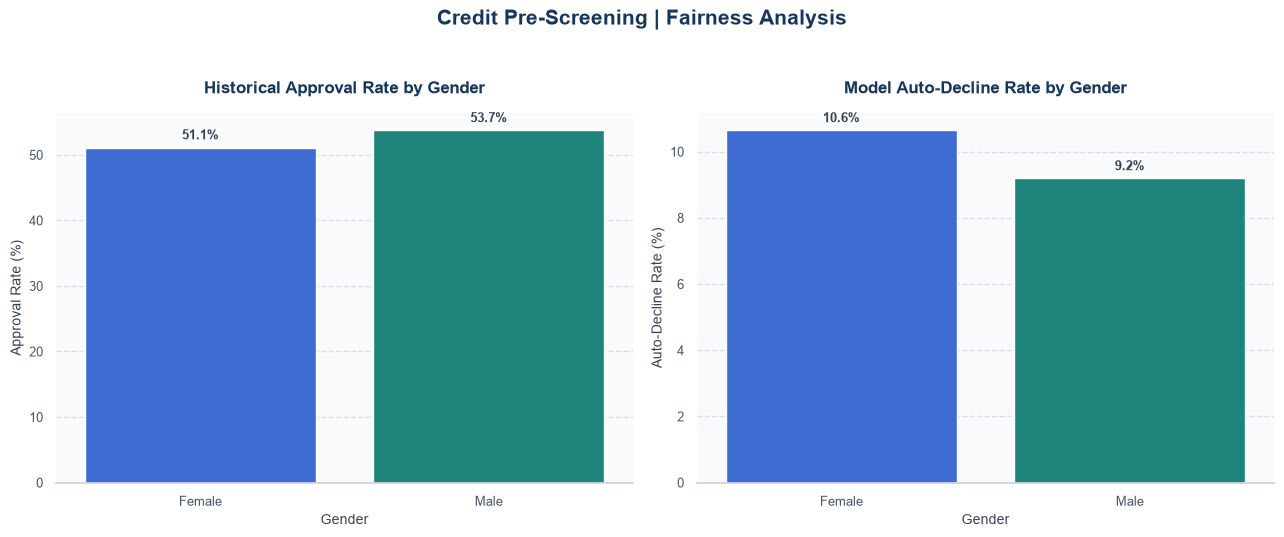

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))

# Consistent colours for gender categories across both charts
gender_values = gender_results.reset_index()["gender"].astype(str).tolist()
palette = ["#2563EB", "#0D9488", "#F97360", "#7C3AED", "#64748B"]
gender_palette = {
    gender: palette[i % len(palette)]
    for i, gender in enumerate(gender_values)
}

# Chart 1: Historical approval rate by gender
sns.barplot(
    data=gender_results.reset_index(),
    x="gender",
    y="historical_approval_pct",
    hue="gender",
    palette=gender_palette,
    legend=False,
    edgecolor="white",
    linewidth=1,
    ax=axes[0]
)

axes[0].set_title(
    "Historical Approval Rate by Gender",
    fontsize=12,
    fontweight="bold",
    color="#17365D",
    pad=14
)
axes[0].set_ylabel("Approval Rate (%)", fontsize=10, color="#334155")
axes[0].set_xlabel("Gender", fontsize=10, color="#334155")

# Add percentage labels
for container in axes[0].containers:
    axes[0].bar_label(
        container,
        fmt="%.1f%%",
        padding=4,
        fontsize=9,
        fontweight="bold",
        color="#334155"
    )

# Chart 2: Model auto-decline rate by gender
sns.barplot(
    data=gender_results.reset_index(),
    x="gender",
    y="model_auto_decline_pct",
    hue="gender",
    palette=gender_palette,
    legend=False,
    edgecolor="white",
    linewidth=1,
    ax=axes[1]
)

axes[1].set_title(
    "Model Auto-Decline Rate by Gender",
    fontsize=12,
    fontweight="bold",
    color="#17365D",
    pad=14
)
axes[1].set_ylabel("Auto-Decline Rate (%)", fontsize=10, color="#334155")
axes[1].set_xlabel("Gender", fontsize=10, color="#334155")

# Add percentage labels
for container in axes[1].containers:
    axes[1].bar_label(
        container,
        fmt="%.1f%%",
        padding=4,
        fontsize=9,
        fontweight="bold",
        color="#334155"
    )

# Apply consistent formal styling
for ax in axes:
    ax.set_facecolor("#F8FAFC")
    ax.grid(axis="y", linestyle="--", alpha=0.3, color="#94A3B8")
    ax.set_axisbelow(True)

    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_visible(False)
    ax.spines["bottom"].set_color("#CBD5E1")

    ax.tick_params(axis="both", labelsize=9, colors="#475569")
    ax.set_ylim(bottom=0)

fig.patch.set_facecolor("white")

fig.suptitle(
    "Credit Pre-Screening | Fairness Analysis",
    fontsize=15,
    fontweight="bold",
    color="#17365D",
    y=1.03
)

plt.tight_layout()
plt.show()

## 12 · Final credit-policy note

Use the validation-selected threshold and report its independent test-set performance. Present the proposed policy as a controlled pilot, not an automatic final lending decision. Include operational safeguards, fairness monitoring, and the need for repayment-outcome data.


Review the generated policy note against the held-out test results before submission. Do not present historical decision prediction as repayment-risk prediction.\n

In [37]:
print("CREDIT POLICY NOTE")
print("=" * 58)
print(f"Historical approval rate: {df['decision'].eq('Approved').mean() * 100:.1f}%.")

lowest_score = score_rate.dropna().idxmin()
print(f"Lowest score-band approval: {score_rate.loc[lowest_score]:.1f}% ({lowest_score}).")
print(f"Approval above 55% FOIR: {foir_rate.loc['Above 55%']:.1f}%.")

if selected_threshold is None:
    print("No tested threshold met the validation 5% rule; keep applications in manual review.")
else:
    print(f"Proposed validation threshold: {selected_threshold:.2f}.")
    print(f"Test wrong-decline share: {final_policy['wrong_pct_of_auto_declines']:.1f}%.")
    print(f"Estimated monthly reviews avoided: {est_monthly_auto:,.0f}; "
          f"estimated hours freed: {est_monthly_hours:,.1f}.")

print("New-to-credit applicants remain in manual review.")
print("Gender is excluded from features, but proxy effects still require monitoring.")
print("The target is historical analyst judgement, not actual repayment.")

CREDIT POLICY NOTE
Historical approval rate: 52.9%.
Lowest score-band approval: 2.0% (Below 600).
Approval above 55% FOIR: 15.6%.
Proposed validation threshold: 0.95.
Test wrong-decline share: 1.3%.
Estimated monthly reviews avoided: 289; estimated hours freed: 120.3.
New-to-credit applicants remain in manual review.
Gender is excluded from features, but proxy effects still require monitoring.
The target is historical analyst judgement, not actual repayment.


## 13 · Deployment safeguards and further validation

Before any production pilot, confirm calibration, subgroup sample sizes, temporal stability, operational appeal routes, and repayment-outcome availability. The historical decision label is not a repayment target.

In [38]:
# Additional validation and governance checklist
deployment_checks = pd.DataFrame({
    "check": [
        "Threshold selected using validation data only",
        "Final policy evaluated once on held-out test data",
        "NTC applications excluded from auto-decline",
        "Gender excluded from model features",
        "Fairness monitored overall and within employment groups",
        "Small subgroup counts flagged",
        "Repayment outcomes available before production use",
        "Out-of-time validation completed before deployment",
        "Human review / appeal process documented",
        "Model calibration and drift monitoring planned"
    ],
    "status": [
        "Yes" if selected_threshold is not None else "No",
        "Yes" if selected_threshold is not None and final_policy is not None else "No",
        "Yes",
        "Yes",
        "Yes",
        "Yes",
        "Not available in current dataset",
        "Not completed in this notebook",
        "Requires operational approval",
        "Requires operational approval"
    ]
})
display(deployment_checks)


,check,status
0,Threshold selected using validation data only,Yes
1,Final policy evaluated once on held-out test data,Yes
2,NTC applications excluded from auto-decline,Yes
3,Gender excluded from model features,Yes
4,Fairness monitored overall and within employme...,Yes
5,Small subgroup counts flagged,Yes
6,Repayment outcomes available before production...,Not available in current dataset
7,Out-of-time validation completed before deploy...,Not completed in this notebook
8,Human review / appeal process documented,Requires operational approval
9,Model calibration and drift monitoring planned,Requires operational approval


# Final Business Insights
### 1. Key Findings ###
Area	Business Insight
Credit Score	Approval increases sharply from 3.2% (600–649) to 32.5% (650–699).
No Credit Score	53.9% approval rate; NTC applicants should receive manual review.
Employment	Gig / Contract workers have the lowest approval rate (34.9%).
FOIR	Approval falls from 65.5% below 30% FOIR to 15.6% above 55%.
Model Accuracy	79.1%, with ROC-AUC of 0.867.
NTC Performance	Only 56.7% accuracy; automated decisions are unreliable for this group.

### 2. Important Model Features ###
Feature	Coefficient	Impact
FOIR	+1.22	Higher FOIR increases decline likelihood.
Credit Score	-1.01	Higher score reduces decline likelihood.
Late Payments	+0.98	More late payments increase decline likelihood.

### 3. Auto-Decline Business Impact ###
Metric	Result
Recommended Threshold	0.90
Auto-Decline Rate	15.2%
Wrong-Decline Share	4.7%
Monthly Applications Automated	456
Monthly Analyst Hours Saved	~190

### 4. Fairness Insights ###
Indicator	Result
Male Approval Rate	54.1%
Female Approval Rate	50.4%
Male Median Income	₹55,000
Female Median Income	₹45,000
Male Gig / Contract Share	12%
Female Gig / Contract Share	21%

Gender exclusion alone does not guarantee fairness because income and employment type may act as indirect proxies.
### 5. Business Recommendations ###
No.	Recommendation
1	Pilot the 0.90 threshold with a strict 5% wrong-decline limit.
2	Keep NTC applicants in manual review.
3	Apply additional affordability checks for FOIR above 50%.
4	Monitor fairness across gender and employment groups.
5	Collect actual repayment and default data before full deployment.
6	Maintain human oversight and regular model monitoring.

### 6. Overall Conclusion ###
The Logistic Regression model can improve loan-screening efficiency by saving approximately 190 analyst hours monthly. However, NTC performance and fairness concerns require human supervision. The model should initially support credit analysts rather than independently make final lending decisions.